# Character vs Subword Tokenization Study

> *How does the choice of tokenization (character vs subword) affect how a language model learns, generalizes, and generates text?*

This notebook is the **research narrative** layer of the project. The reusable code lives in [`../src/`](../src/); here we use it to run experiments, visualise results, and discuss what we see.

Outline:

1. Setup
2. Corpus
3. Exploring the dataset with pandas
4. What do we mean by a "token"?
5. Build the two tokenizers
6. Vocabulary analysis
7. Sequence-length comparison
8. The model — MiniGPT architecture
9. Train both models
10. Loss curves & convergence
11. Generation samples
12. Robustness to rare / unseen words
13. Discussion & insights

## 1. Setup

In [1]:
import sys, os
from pathlib import Path

# make `src` importable when the notebook is run from /notebooks
ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import math
import re
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.char_tokenizer import CharTokenizer
from src.subword_tokenizer import SubwordTokenizer
from src.utils import load_corpus, split_corpus

plt.rcParams['figure.figsize'] = (9, 4)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DEVICE

'cpu'

## 2. Corpus

We use our **[Shakespeare for NLP](https://www.kaggle.com/datasets/ismailalshofi/shakespeare-for-nlp-91k-tagged-lines)** dataset — published on Kaggle, also committed to this repo at [`../data/shakespeare_lines.csv`](../data/shakespeare_lines.csv). All 37 plays, every spoken line, with `play / act / scene / player / line_text` columns. We curated it from the Folger TEI XML hosted by [dracor-org/shakedracor](https://github.com/dracor-org/shakedracor) — stage directions stripped, speeches grouped, smart punctuation preserved.

`load_corpus()` collapses the CSV back into a single text string in the classic Tiny-Shakespeare format — speaker label on its own line, then the speech, blank line between speeches — so the rest of the pipeline (tokenizers, model) doesn't need to know it came from a structured source.

In [2]:
CSV_PATH = ROOT / 'data' / 'shakespeare_lines.csv'
text = load_corpus(CSV_PATH)
train_text, val_text = split_corpus(text)

print(f'total chars: {len(text):,}')
print(f'train chars: {len(train_text):,}')
print(f'val   chars: {len(val_text):,}')
print('\n--- sample ---')
print(text[:400])

total chars: 4,581,954
train chars: 4,123,758
val   chars: 458,196

--- sample ---
THESEUS:
Now, fair Hippolyta, our nuptial hour
Draws on apace. Four happy days bring in
Another moon. But, O, methinks how slow
This old moon wanes! She lingers my desires
Like to a stepdame or a dowager
Long withering out a young man’s revenue.

HIPPOLYTA:
Four days will quickly steep themselves in night;
Four nights will quickly dream away the time;
And then the moon, like to a silver bow
New-be


### What we see

The dataset is about **8 MB** on disk (the structured CSV). Once we drop the metadata columns and keep only the dialogue text, we get about 4.5M characters — roughly 4× bigger than the classic Tiny Shakespeare file people use to test small language models.

Notice the shape: speaker name in CAPS, then a colon on its own line, then the lines they speak, blank lines between speakers. This is what LM training data usually looks like.

The tokenizers don't know any of this. They see the text as one long string. The model has to learn the "this is a speaker label" pattern on its own. How well each tokenizer helps the model do that is a big part of what we're testing.

## 3. Exploring the dataset with pandas

Before we tokenize anything, it helps to actually look at what we're working with. We've been treating the corpus as one big text blob, but it started life as a structured CSV. Loading it as a DataFrame lets us ask some basic questions in a couple of lines: how many plays are in here, who talks the most, how long lines tend to be. None of this is the *result* of the study — it's just the kind of look-around you'd do at the start of any data project to build intuition for what the model and the tokenizer are actually going to see.

In [3]:
df = pd.read_csv(CSV_PATH)
print('shape:', df.shape)
df.head()

shape: (91509, 7)


,play,play_title,act,scene,player,line_number,line_text
0,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.1,"Now, fair Hippolyta, our nuptial hour"
1,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.2,Draws on apace. Four happy days bring in
2,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.3,"Another moon. But, O, methinks how slow"
3,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.4,This old moon wanes! She lingers my desires
4,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.5,Like to a stepdame or a dowager


One row per spoken line, with the play, act, scene, speaker, the Folger line number, and the line of text itself. Let's get the high-level counts:

In [4]:
print(f"plays:    {df['play'].nunique():>6}")
print(f"scenes:   {df.groupby(['play','act','scene']).ngroups:>6,}")
print(f"speakers: {df['player'].nunique():>6,}")
print(f"lines:    {len(df):>6,}")

plays:        37
scenes:      745
speakers:    955
lines:    91,509


950 speakers sounds like a lot. The reason is that `player` is the raw label from the script. `KING`, `KING HENRY`, and `KING HENRY V` count as three different speakers, even though they may be the same person across plays. We're leaving them as-is — fixing this is a different problem, and we don't need to solve it to study tokenization.

### Who talks the most?

A quick `value_counts()` gives us the most prolific speakers across the whole corpus:

In [5]:
df['player'].value_counts().head(15).to_frame('lines')

,lines
player,
KING,2300
KING HENRY,1748
RICHARD,1659
ANTONY,1165
DUKE,1110
HAMLET,1095
YORK,974
BRUTUS,938
IAGO,881


The top of the list is full of generic role labels (`KING`, `DUKE`, `PRINCE`) that show up across many plays. Past those, real named characters appear: Hamlet, Iago, Brutus, Antony, Falstaff. That makes sense — those are the long, talky leads.

### Lines per play

Which plays are the wordiest? Sorting plays by the number of spoken lines gives a rough proxy for length:

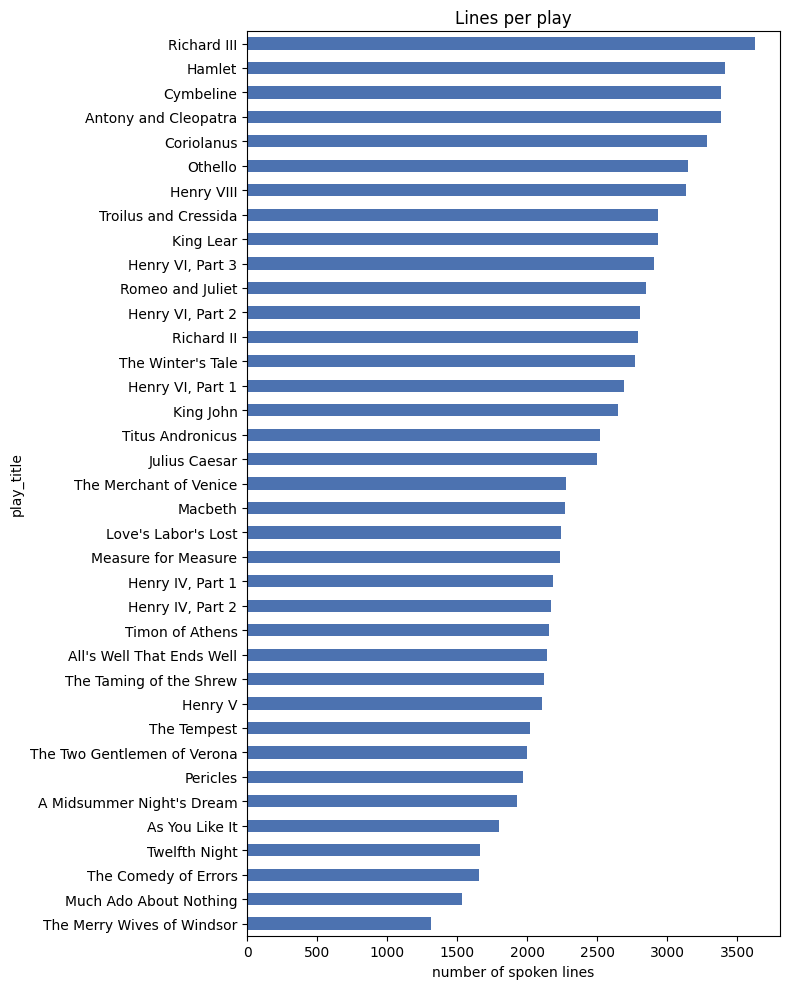

In [6]:
lines_per_play = df['play_title'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 10))
lines_per_play.plot.barh(ax=ax, color='#4C72B0')
ax.set_xlabel('number of spoken lines')
ax.set_title('Lines per play')
plt.tight_layout()
fig.savefig(ROOT / 'results' / 'lines_per_play.png', dpi=150)
plt.show()

*Richard III*, *Hamlet*, *Cymbeline*, and *Antony and Cleopatra* are the longest. *The Merry Wives of Windsor* is the shortest. The longest play is only about 2× the shortest, so no play takes over the corpus. The training data is fairly balanced across all 37 plays.

### How long is a line?

Shakespeare's verse is roughly iambic pentameter — ten syllables, ~40 characters — but lots of lines are short interjections (`Who's there?`) or shared lines split between speakers. Let's look at the distribution:

In [7]:
df['line_chars'] = df['line_text'].str.len()
df['line_words'] = df['line_text'].str.split().str.len()
df[['line_chars', 'line_words']].describe().round(1)

,line_chars,line_words
count,91509.0,91509.0
mean,45.5,8.8
std,52.3,10.1
min,2.0,1.0
25%,36.0,6.0
50%,41.0,8.0
75%,45.0,9.0
max,2055.0,414.0


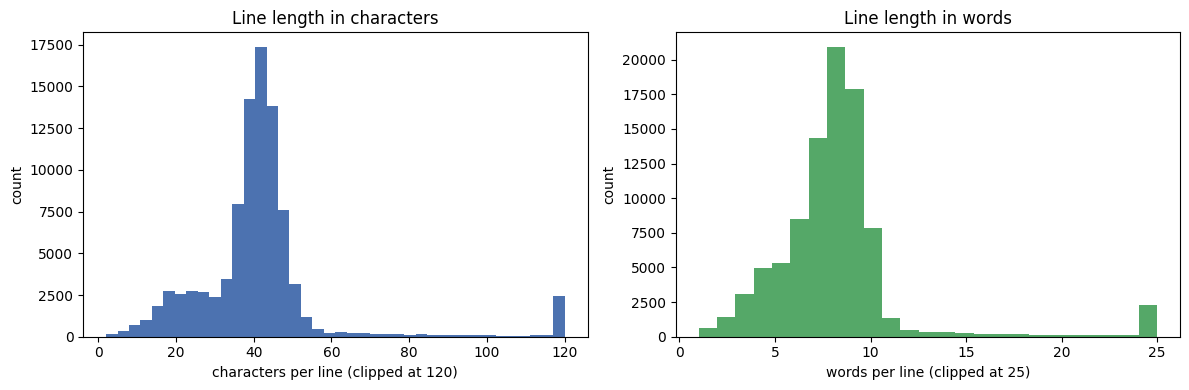

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['line_chars'].clip(upper=120), bins=40, color='#4C72B0')
axes[0].set_xlabel('characters per line (clipped at 120)')
axes[0].set_ylabel('count')
axes[0].set_title('Line length in characters')

axes[1].hist(df['line_words'].clip(upper=25), bins=25, color='#55A868')
axes[1].set_xlabel('words per line (clipped at 25)')
axes[1].set_ylabel('count')
axes[1].set_title('Line length in words')

plt.tight_layout()
fig.savefig(ROOT / 'results' / 'line_length.png', dpi=150)
plt.show()

The median line is about **40 characters / 8 words**. That's iambic pentameter — Shakespeare's standard verse line. The left tail (short lines) is one-word interjections and names. The right tail (long lines) is prose passages. This shape matters later: when we look at how many tokens each line becomes after tokenization, this is the starting distribution.

### A scene at a glance

Finally, since we have the structure, we can pull a single scene out cleanly — something that's awkward to do from raw text but trivial in pandas:

In [9]:
scene = df[(df['play']=='hamlet') & (df['act']==3) & (df['scene']==1)]
print(f"Hamlet, Act 3 Scene 1 — {len(scene)} lines, {scene['player'].nunique()} speakers\n")
for _, row in scene.head(12).iterrows():
    print(f"  {row['player']:>10}: {row['line_text']}")

Hamlet, Act 3 Scene 1 — 166 lines, 7 speakers

        KING: And can you by no drift of conference
        KING: Get from him why he puts on this confusion,
        KING: Grating so harshly all his days of quiet
        KING: With turbulent and dangerous lunacy?
  ROSENCRANTZ: He does confess he feels himself distracted,
  ROSENCRANTZ: But from what cause he will by no means speak.
  GUILDENSTERN: Nor do we find him forward to be sounded,
  GUILDENSTERN: But with a crafty madness keeps aloof
  GUILDENSTERN: When we would bring him on to some confession
  GUILDENSTERN: Of his true state.
       QUEEN: Did he receive you well?
  ROSENCRANTZ: Most like a gentleman.


That's the opening of the "To be, or not to be" scene. The point isn't the literature — it's that having the data in this structured form lets us pull out a specific scene in one line of pandas. We'll use that later for questions like "how does the model handle Hamlet's prose vs the King's verse?"

## 4. What do we mean by a "token"?

Before we build tokenizers, it's worth pinning down what *a token* even is. The word gets used loosely in NLP — it can mean a single character, a piece of a word, a whole word, or in some pipelines a whole sentence. The choice of granularity is one of the biggest design knobs in the whole field. It changes vocabulary size, it changes sequence length, and it changes what the model has to learn from scratch versus what it gets for free.

Here's the spectrum, from finest to coarsest, applied to a familiar line:

| Granularity | Example tokens for *"To be, or not to be"* | Vocab size | Sequence length | Where it shows up |
| --- | --- | --- | --- | --- |
| **Character** | `T`, `o`, ` `, `b`, `e`, `,`, ` `, `o`, `r`, … | tiny (~100) | very long | char-RNN, ByT5, anything that needs to handle arbitrary text without a vocab |
| **Subword (BPE)** | `To`, ` be`, `,`, ` or`, ` not`, ` to`, ` be` | medium (~8k–100k) | medium | GPT, BERT, LLaMA — basically every modern LLM |
| **Word** | `To`, `be`, `or`, `not`, `to`, `be` | large (~50k–1M) | short | classic NLP (word2vec, early LSTMs), still common in retrieval |
| **Sentence** | `"To be, or not to be"` (one token) | huge | very short | sentence embedders for retrieval / clustering, *not* used for generation |

A few things worth noticing in that table:

- **Vocab size and sequence length pull in opposite directions.** Finer-grained tokens means a smaller vocab (cheaper embedding and output layers) but more tokens per document (more compute in attention, which is O(T²)). Coarser-grained tokens flips both.
- **No granularity is "right."** Each one is a different bet about what the model should figure out on its own. Char tokenizers force the model to learn spelling from scratch but never have an out-of-vocabulary problem. Word tokenizers hand the model whole words but choke the moment they see something not in the dictionary. Subword sits in the middle and is the modern default.
- **"Sentence tokens" aren't really for generation.** You can't autoregressively predict the next *sentence* the way you predict the next character — the vocab would be effectively infinite. Sentence-level tokens show up in retrieval and embedding pipelines ("is this sentence similar to that one?"), not in language modeling.

Our study compares the two extremes that matter for generative modeling: **character** (one extreme) versus **subword/BPE** (the modern default). Same model, same data, same training budget — only the tokenizer changes.

### Seeing the four granularities side-by-side

Let's run a real sentence through each of them. For the subword example we'll just illustrate what a BPE tokenizer would do (we haven't trained ours yet — that's the next section). The character and word splits are exact; the sentence "tokenizer" is just a naive split on `.!?`.

In [10]:
sample = "To be, or not to be, that is the question."

char_tokens = list(sample)
word_tokens = sample.split()
# illustrative BPE output (real BPE would learn its own merges from the corpus)
bpe_tokens  = ['To', ' be', ',', ' or', ' not', ' to', ' be', ',', ' that', ' is', ' the', ' question', '.']

longer = "Hamlet thinks aloud. To be, or not to be? That is the question."
sent_tokens = re.split(r'(?<=[.!?])\s+', longer)

print(f"character  ({len(char_tokens):>2} tokens): {char_tokens}")
print()
print(f"subword    ({len(bpe_tokens):>2} tokens): {bpe_tokens}")
print()
print(f"word       ({len(word_tokens):>2} tokens): {word_tokens}")
print()
print(f"sentence   ({len(sent_tokens):>2} tokens): {sent_tokens}")

character  (42 tokens): ['T', 'o', ' ', 'b', 'e', ',', ' ', 'o', 'r', ' ', 'n', 'o', 't', ' ', 't', 'o', ' ', 'b', 'e', ',', ' ', 't', 'h', 'a', 't', ' ', 'i', 's', ' ', 't', 'h', 'e', ' ', 'q', 'u', 'e', 's', 't', 'i', 'o', 'n', '.']

subword    (13 tokens): ['To', ' be', ',', ' or', ' not', ' to', ' be', ',', ' that', ' is', ' the', ' question', '.']

word       (10 tokens): ['To', 'be,', 'or', 'not', 'to', 'be,', 'that', 'is', 'the', 'question.']

sentence   ( 3 tokens): ['Hamlet thinks aloud.', 'To be, or not to be?', 'That is the question.']


The same sentence, four different ways to slice it:

- **Character** — 42 tokens. Every letter, space, and comma counts.
- **Subword** — 13 tokens. Common pieces like `To`, ` be`, ` the` merge into single units.
- **Word** — 10 tokens. One token per space-separated chunk.
- **Sentence** — 1 token (or a few). The whole thing in one piece.

The rest of this notebook is about what happens when we train *the same model* on the *same text* using **character** and **subword** — the two choices that matter for text generation.

## 5. Build the two tokenizers

Both tokenizers are trained on the **same training split** with the same special tokens, so the only thing that differs is the unit of representation.

In [11]:
char_tok = CharTokenizer().train([train_text])
sub_tok = SubwordTokenizer().train([train_text], vocab_size=8000)

print(f'char    vocab size: {char_tok.vocab_size:>6}')
print(f'subword vocab size: {sub_tok.vocab_size:>6}')

char    vocab size:     97
subword vocab size:   8000


### Where do these numbers come from?

**Char ≈ 70** is not a choice. It's just every distinct character in the corpus (uppercase letters, lowercase letters, punctuation, whitespace) plus our 4 special tokens (`<pad>`, `<unk>`, `<bos>`, `<eos>`).

**Subword = 8000** *is* a choice we made. BPE starts with single bytes (~256 of them) and learns merges (`t`+`h` → `th`, then `th`+`e` → `the`, and so on) until it hits the vocab limit we set. 8000 is a common default for small corpora. For comparison: LLaMA uses 32K, GPT-4 uses about 100K.

### Now let's tokenize that same sentence with the real BPE

Section 4 showed an illustrative BPE split. Now that we have a tokenizer actually trained on Shakespeare, we can see what merges it learned:

In [12]:
sample = "To be, or not to be, that is the question."
real_bpe = [sub_tok._tok.id_to_token(i) for i in sub_tok.encode(sample)]
print(f"real BPE ({len(real_bpe)} tokens): {real_bpe}")

real BPE (13 tokens): ['To', 'Ġbe', ',', 'Ġor', 'Ġnot', 'Ġto', 'Ġbe', ',', 'Ġthat', 'Ġis', 'Ġthe', 'Ġquestion', '.']


The `Ġ` characters mark the start of a word — they're how byte-level BPE encodes a space (HuggingFace convention). Two things to notice: `question` is one whole token, and common openings like `To` and `be` are single tokens too. Those merges were learned from the corpus. That's why BPE trained on Shakespeare looks different from BPE trained on, say, scientific papers.

## 6. Vocabulary analysis

Two questions:

- **How big is each vocabulary?**
- **How is token frequency distributed?** Subword vocabularies tend to follow a long-tailed (Zipfian) distribution; character vocabularies are much flatter.

In [13]:
char_ids = char_tok.encode(train_text)
sub_ids  = sub_tok.encode(train_text)

char_counts = collections.Counter(char_ids)
sub_counts  = collections.Counter(sub_ids)

summary = pd.DataFrame({
    'tokenizer': ['char', 'subword'],
    'vocab_size': [char_tok.vocab_size, sub_tok.vocab_size],
    'tokens_in_train': [len(char_ids), len(sub_ids)],
    'avg_chars_per_token': [len(train_text)/len(char_ids), len(train_text)/len(sub_ids)],
})
summary

,tokenizer,vocab_size,tokens_in_train,avg_chars_per_token
0,char,97,4123758,1.000000
1,subword,8000,1203333,3.426947


### The compression ratio is the key number

On average, one subword token covers about **3.5 characters** of text. That single number explains most of the trade-off in this study:

- For the same sentence, the subword model sees **~3.5× fewer tokens**.
- For the same context window (`block_size`), the subword model sees **~3.5× more text**.
- The subword model has more *parameters* (because the vocab is bigger) but processes fewer *tokens* per step.

Those two effects pull in opposite directions. Which one wins depends on the corpus, the model size, and how long we train.

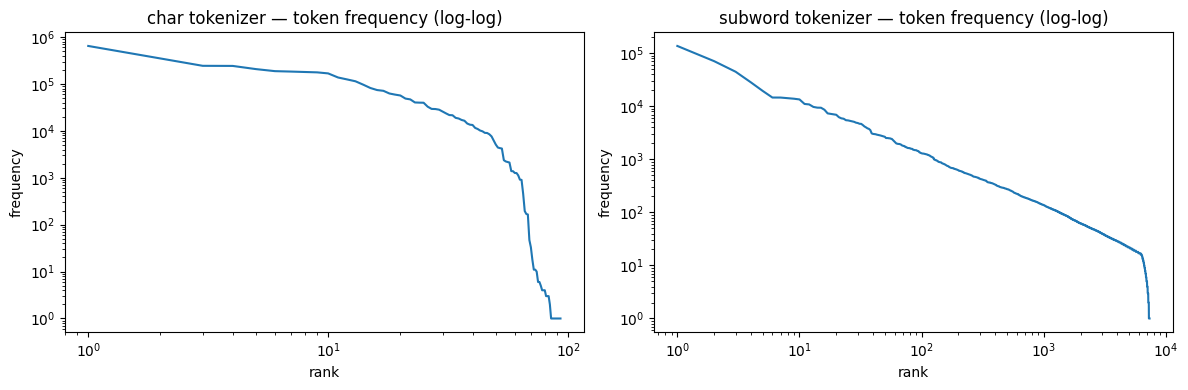

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in [
    (axes[0], char_counts, 'char tokenizer'),
    (axes[1], sub_counts, 'subword tokenizer'),
]:
    freqs = sorted(counts.values(), reverse=True)
    ax.loglog(range(1, len(freqs)+1), freqs)
    ax.set_title(f'{title} — token frequency (log-log)')
    ax.set_xlabel('rank')
    ax.set_ylabel('frequency')
fig.tight_layout()
fig.savefig(ROOT / 'results' / 'token_frequency.png', dpi=150)
plt.show()

### Reading the frequency plots

Both plots use **log-log axes**. On these axes, a straight line means the distribution follows a power law — that's Zipf's law (frequency ∝ 1/rank).

**Char plot** — short and pretty flat near the top. The most common characters (space, `e`, `t`, `a`, `o`) all have similar frequencies. There's no long tail because there's almost no vocabulary to have a tail in.

**Subword plot** — long and steep. A handful of tokens dominate (common words and word-pieces). Thousands of tokens show up only a few times each. That long tail is the problem: rare tokens get few updates during training, so their embeddings are hard to learn.

**So:** the subword model has to spend learning effort on tokens it barely sees. The char model doesn't have this problem.

## 7. Sequence-length comparison

For the same text, the char tokenizer produces a much longer ID sequence. This directly drives compute cost during training and inference, and bounds how much context fits in a given `block_size`.

In [15]:
# split by blank lines to get pseudo-"documents" (one speech each)
docs = [d for d in text.split('\n\n') if d.strip()]
char_lens = np.array([len(char_tok.encode(d)) for d in docs])
sub_lens  = np.array([len(sub_tok.encode(d))  for d in docs])

stats = pd.DataFrame({
    'tokenizer': ['char', 'subword'],
    'mean_len': [char_lens.mean(), sub_lens.mean()],
    'median_len': [np.median(char_lens), np.median(sub_lens)],
    'p95_len': [np.percentile(char_lens, 95), np.percentile(sub_lens, 95)],
})
stats.round(1)

,tokenizer,mean_len,median_len,p95_len
0,char,146.3,75.0,504.0
1,subword,41.7,22.0,141.0


### The 3.5× compression shows up at every percentile

The subword sequences are 3–4× shorter than the char sequences everywhere — average speeches, long speeches, and short ones.

**Why this matters:** if you want most of your documents to fit in one chunk, the subword model lets you use a context window about 3.5× smaller for the same coverage. Since attention cost is O(T²), that's roughly a **12× cheaper** training step.

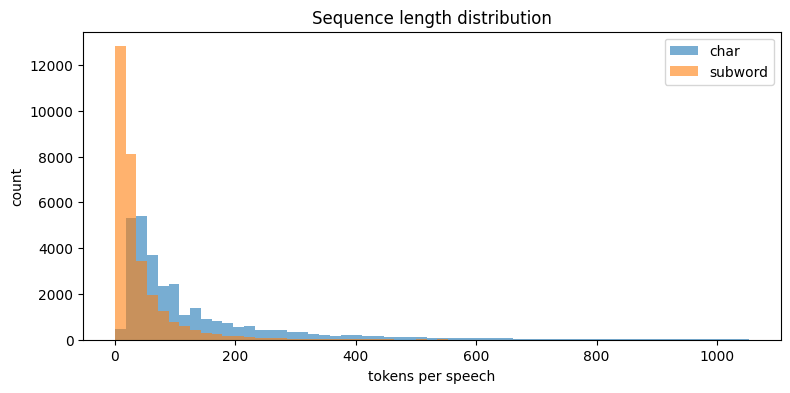

In [16]:
fig, ax = plt.subplots()
bins = np.linspace(0, np.percentile(char_lens, 99), 60)
ax.hist(char_lens, bins=bins, alpha=0.6, label='char')
ax.hist(sub_lens,  bins=bins, alpha=0.6, label='subword')
ax.set_xlabel('tokens per speech')
ax.set_ylabel('count')
ax.set_title('Sequence length distribution')
ax.legend()
fig.savefig(ROOT / 'results' / 'sequence_lengths.png', dpi=150)
plt.show()

### Distribution shape

Both distributions are right-skewed: most speeches are short, a few are very long. But the subword distribution is squashed toward zero. That long right tail in the char distribution is the headache — you either truncate long speeches, or you set a bigger context window. Either choice costs you something.

## 8. The model — MiniGPT architecture

To isolate the effect of tokenization, both runs use the **same** small Transformer decoder defined in [`src/model.py`](../src/model.py). The only thing that changes between runs is the `vocab_size` (and therefore the size of the embedding and output layers).

### Architecture at a glance

```
       input token IDs    shape: (batch, sequence)
              │
              ▼
    ┌─────────────────────┐
    │  Token Embedding    │  ← turn each ID into a learned vector
    │       +             │
    │  Position Embedding │  ← add a learned vector for each position
    └─────────────────────┘
              │
              ▼
    ┌─────────────────────┐
    │  Transformer Block  │  ┐
    └─────────────────────┘  │  repeated N times
              ⋮              │
    ┌─────────────────────┐  │
    │  Transformer Block  │  ┘
    └─────────────────────┘
              │
              ▼
         LayerNorm
              │
              ▼
    ┌─────────────────────┐
    │  Linear → vocab     │  ← logits for the next token
    └─────────────────────┘
```

### One Transformer Block

```
                        ┌────────── residual ──────────┐
                        │                              │
    x ──► LayerNorm ──► CausalSelfAttention ──► (+) ──┐│
                                                      ▼│
                        ┌────────── residual ──────────┘
                        │                              │
                        ▼                              │
                      LayerNorm ──► MLP ──► (+) ───────┴──► x
```

### Key design choices (and why)

| Choice | What it does | Why this choice |
| --- | --- | --- |
| **Causal mask** | Each position can only attend to itself and earlier positions | Makes it a *decoder*: the model generates left-to-right and can be trained with simple next-token prediction |
| **Multi-head attention** | Splits the embedding into `n_head` parallel "heads" | Lets the model attend to different relationships at once (one head might track syntax, another long-range references) |
| **Pre-norm** | LayerNorm goes *before* attention/MLP, not after | More stable training for deep stacks — this is the modern GPT-style ordering |
| **Residual connections** | Each sublayer adds its output to its input | Lets gradients flow through the stack and lets each block learn an *increment* to the representation |
| **Learned positional embeddings** | Each position 0..block_size gets its own vector | Simpler than sinusoidal; works fine at this scale |

### Where tokenization shows up in the model

Two layers depend directly on `vocab_size`:

- **`tok_emb`** — the token embedding table. One vector per vocabulary entry.
- **`head`** — the final linear layer that produces logits over the vocabulary.

The Transformer blocks in between are *identical* across runs. Let's see how big the difference is in practice:

In [17]:
from src.model import GPTConfig, MiniGPT

def model_summary(tokenizer, label):
    # Same config as the training runs (src/train.py defaults)
    cfg = GPTConfig(vocab_size=tokenizer.vocab_size, block_size=256,
                    n_layer=4, n_head=4, n_embd=256)
    model = MiniGPT(cfg)
    total = sum(p.numel() for p in model.parameters())
    emb   = sum(p.numel() for p in model.tok_emb.parameters())
    head  = sum(p.numel() for p in model.head.parameters())
    rest  = total - emb - head
    print(f'[{label:>7}] vocab={tokenizer.vocab_size:>5}  '
          f'total={total:>9,}  tok_emb={emb:>8,}  head={head:>8,}  rest={rest:>8,}')

model_summary(char_tok, 'char')
model_summary(sub_tok, 'subword')

[   char] vocab=   97  total=3,274,752  tok_emb=  24,832  head=  24,832  rest=3,225,088
[subword] vocab= 8000  total=7,321,088  tok_emb=2,048,000  head=2,048,000  rest=3,225,088


### What this tells us

The subword model has **a lot more parameters** than the char model. But almost all of the extra parameters sit in the embedding and output layers — the parts that depend on vocab size. The Transformer blocks in the middle (the part that does the "thinking") are exactly the same in both models.

**Important caveat:** when we compare the two models, we're not comparing two equally-sized models. The subword model is bigger. For a strictly fair comparison we'd either shrink the subword embedding to match parameter count, or just keep this asymmetry in mind when reading the results.

## 9. Train both models

Both models were trained with the CLI on a free Kaggle GPU (T4), with the same settings: 4 layers, 4 heads, 256-dim embeddings, a context of 256 tokens, batch 64, 2000 steps, AdamW at 3e-4. Only the tokenizer changes.

```bash
python -m src.train --tokenizer char    --out results/char
python -m src.train --tokenizer subword --out results/subword
```

([`notebooks/kaggle_run.ipynb`](kaggle_run.ipynb) runs both.) Each run writes `summary.json`, `history.json` and a generation sample to `results/`, and this section loads them.

In [18]:
RESULTS = ROOT / 'results'
runs = {t: json.loads((RESULTS / t / 'summary.json').read_text()) for t in ('char', 'subword')}
histories = {t: json.loads((RESULTS / t / 'history.json').read_text()) for t in ('char', 'subword')}

table = pd.DataFrame(runs).T[['vocab_size', 'n_params', 'chars_per_token', 'val_loss', 'val_perplexity', 'val_bpc', 'train_time_s']]
table.astype(float).round(3)

,vocab_size,n_params,chars_per_token,val_loss,val_perplexity,val_bpc,train_time_s
char,97.0,3274752.0,1.000,1.664,5.279,2.400,313.045
subword,8000.0,7321088.0,3.147,4.531,92.841,2.077,449.580


### Reading these numbers carefully

The raw validation losses (**1.66** for char, **4.53** for subword) make it look like the char model wins by a mile. **It doesn't.** They are cross-entropies over different vocabularies: picking 1 of 97 characters vs picking 1 of 8000 subwords, where each subword carries about 3 characters of text.

The fair metric is **bits per character (bpc)**: the loss spread over the characters it actually predicts.

```
bpc = nats_per_token / chars_per_token / ln(2)
```

On the validation text, a subword token covers **3.15 characters** (a bit less than on the training text, because the BPE merges were learned there). In bpc the order flips:

| | val loss | bpc |
|---|---|---|
| char | 1.66 | **2.40** |
| subword | 4.53 | **2.08** |

The subword model needs about 13% fewer bits per character.

## 10. Learning curves & convergence

Validation bpc against training step, and against wall-clock time on the same GPU.

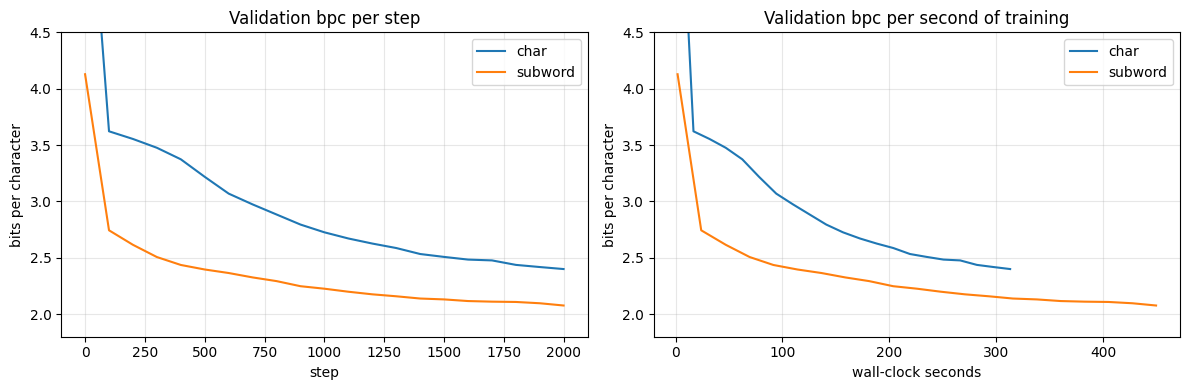

same training time (313s): char 2.40  subword 2.14
same amount of text seen:        char 2.40  subword 2.35  (subword step 635)
    char: train bpc 2.37  val bpc 2.44  gap 0.07
 subword: train bpc 1.91  val bpc 2.10  gap 0.19


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, hist in histories.items():
    steps = [h['step'] for h in hist]
    secs  = [h['elapsed_s'] for h in hist]
    bpc   = [h['val_bpc'] for h in hist]
    axes[0].plot(steps, bpc, label=label)
    axes[1].plot(secs, bpc, label=label)
axes[0].set_xlabel('step');               axes[0].set_title('Validation bpc per step')
axes[1].set_xlabel('wall-clock seconds'); axes[1].set_title('Validation bpc per second of training')
for ax in axes:
    ax.set_ylabel('bits per character'); ax.set_ylim(1.8, 4.5); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
fig.savefig(RESULTS / 'loss_curves.png', dpi=150)
plt.show()

def bpc_at(hist, key, x):
    for a, b in zip(hist, hist[1:]):
        if a[key] <= x <= b[key]:
            f = (x - a[key]) / (b[key] - a[key])
            return a['val_bpc'] + f * (b['val_bpc'] - a['val_bpc'])

char_h, sub_h = histories['char'], histories['subword']
cpt = runs['subword']['chars_per_token']
same_time = char_h[-1]['elapsed_s']
same_text = 2000 / cpt  # the subword step that has seen as much text as 2000 char steps
print(f"same training time ({same_time:.0f}s): char {char_h[-1]['val_bpc']:.2f}  subword {bpc_at(sub_h, 'elapsed_s', same_time):.2f}")
print(f"same amount of text seen:        char {char_h[-1]['val_bpc']:.2f}  subword {bpc_at(sub_h, 'step', same_text):.2f}  (subword step {same_text:.0f})")

for label, hist, c in (('char', char_h, 1.0), ('subword', sub_h, cpt)):
    last = hist[-5:]
    train = sum(h['train_loss'] for h in last) / len(last) / math.log(2) / c
    val   = sum(h['val_bpc'] for h in last) / len(last)
    print(f'{label:>8}: train bpc {train:.2f}  val bpc {val:.2f}  gap {val - train:.2f}')

### What the curves say

- **Subword learns faster per step.** After 400 steps it is at 2.44 bpc; char is at 3.37.
- **It still wins at the same training time.** At 313 s, when the char run ends, the subword model is at 2.14 vs 2.40.
- **But most of the win is extra text, not a better tokenizer.** With the same context of 256 tokens, every subword step sees ~3x more text. Compared at the **same amount of text seen**, the gap almost closes: **2.35 vs 2.40**.
- **The subword model is starting to memorise.** Its train/val gap is about 0.19 bpc against 0.07 for char. It has 7.3M parameters against 3.3M, and the extra 4M are all in the embedding and output layers, on a 9 MB corpus.
- **The char model hasn't converged.** Its curve is still dropping twice as fast as the subword one at the end (0.08 vs 0.04 bpc over the last 400 steps). With a longer run the gap would likely shrink further.

## 11. Generation samples

Each run wrote a sample at the end of training: 400 new tokens from a newline, temperature 0.9, top-k 40. 400 tokens is ~400 characters for char and ~1,250 for subword.

In [20]:
for label in ('char', 'subword'):
    print(f'=== {label} ===')
    print((RESULTS / label / 'sample.txt').read_text(encoding='utf-8')[:700].strip())
    print()

=== char ===
LUFFERLAND:
What dwarwick of eye deep to follo me this bounds.

TONIOLANUS:
For you action, must deservity, liked.

KING:
Of Where you as a false helphed my knave, medy adval of hee compance-as of the lady
As what hathle soul to him
Is be may you pasers, what I thou do leave to,
And sick one law to know
Who that know our hanners stand the leart.
I how for me, I am be do no nasomise defender a pain

=== subword ===
FIRST LORD:
And so, my lord,
I have been not of mine honor of it,
Which now a man
When I should not be. This shall be made
In any that I will not fear
To think
To have the King hath received.

BRUTUS:
I hope, madam.

SECOND GENTLEMAN:
But I will tell you,
And let you have heard it, my lord,
That you have my country.

KING HENRY:I will not think I am
And will, madam, in the Duke of York’s
And bid him not, as I may have.
If we hear what we will be
I shall have them stay.
Yet, good faith, if
He’s a Roman father should be his death
And you can know by the King,
And t

### What we see

**Char model.** The page looks right: speaker names in capitals, colons, verse line breaks, punctuation. Many words are real (*action*, *knave*, *defender*), but it also invents its own: *dwarwick*, *deservity*, *nasomise*. It only knows letters, so every word is something it has to build one letter at a time.

**Subword model.** Every word is a real word, and the speaker names are real characters (Brutus, Iago, Desdemona, King Henry). Short lines like *"You shall not go."* and *"My father did it."* read like Shakespeare. It still doesn't hold a thought for more than a line or two.

Neither model is coherent; at 3-7M parameters and 2000 steps, that was never the goal. The difference is the **level** of the mistakes: char makes spelling mistakes, subword makes meaning mistakes.

**Fair-comparison note:** 400 tokens is not the same amount of text for both models, so compare the quality of the lines, not the length.

## 12. Robustness to rare / unseen words

How does each tokenizer represent things it hasn't really seen? Try made-up words, typos, and rare proper nouns.

In [21]:
probes = [
    'antidisestablishmentarianism',
    'teh quik brwn fox',
    'Ozymandias',
    '\u4f60\u597d\u4e16\u754c',  # "hello world" in Chinese — likely unseen
]
rows = []
for p in probes:
    rows.append({
        'text': p,
        'char_tokens': len(char_tok.encode(p)),
        'subword_tokens': len(sub_tok.encode(p)),
    })
pd.DataFrame(rows)

,text,char_tokens,subword_tokens
0,antidisestablishmentarianism,28,12
1,teh quik brwn fox,17,9
2,Ozymandias,10,5
3,你好世界,4,12


### Watch out: token count hides what's really happening

The Chinese row makes it look like the char tokenizer *wins* — 4 tokens vs 12. It doesn't.

- The char tokenizer turns `你好世界` into **4 `<unk>` tokens**. All four are the same token. The model has no way to tell `你好世界` apart from `xxxx` or any other unseen 4-character string.
- The subword tokenizer uses 12 tokens via **byte-level fallback**. Each Chinese character is 3 UTF-8 bytes, and BPE keeps them. Nothing is lost — you can recover the exact original bytes.

So the real robustness story is the opposite of what the table suggests:

- **Char tokenizer** fails *silently* on unknown scripts — everything collapses to `<unk>`.
- **Subword tokenizer** degrades *gracefully* — longer encoding, but no information lost.

To show this properly we should add a column counting `<unk>` tokens. That would turn a misleading comparison into a useful one.

## 13. Discussion & insights

What this study showed:

- **Vocabulary.** The char tokenizer has 97 symbols, the BPE tokenizer 8000. That alone makes the subword model 2.2x larger (7.3M vs 3.3M parameters): the extra 4M sit in the embedding and output layers, the Transformer blocks are identical.
- **Sequence length.** For the same text, subword sequences are about 3x shorter. With the same context window, the subword model sees about 3x more text per step.
- **Quality.** In bits per character, subword wins: **2.08 vs 2.40**. Raw loss would have said the opposite (4.53 vs 1.66), which is why the metric matters more than the number.
- **Where the win comes from.** At equal training time subword still wins (2.14 vs 2.40). At an equal amount of text seen, it barely does (2.35 vs 2.40). Most of the advantage is the wider view per step, not a better way of reading text.
- **Cost.** Each subword step was ~44% slower on the GPU (450 s vs 313 s), from the 8000-way output layer. It is also the model that started to overfit first.
- **Generation.** Char makes spelling mistakes; subword makes meaning mistakes.
- **Robustness.** Char fails silently on unseen scripts (everything becomes `<unk>`). Subword degrades gracefully via byte-level fallback: longer, but nothing is lost.

**Bottom line:** tokenization is not "just preprocessing". It changes how big the model is, how much text one step sees, what kind of mistakes it makes, and what a "fair" comparison even means.

**Next steps:** match the context in characters instead of tokens, tie the embedding and output weights so the parameter counts are closer, and train longer to see where the char curve flattens.